In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("transactions_TP2.csv")

In [3]:
df.head()

,id_operation,id_client,montant_dh,anciennete_mois,nb_ops_24h,heure,canal,appareil,region,international,resultat_enquete,fraude
0,OP02438,C10278,5396.62,90.0,6.0,11,site_web,mobile,Marrakech-Safi,non,aucune_fraude,0
1,OP00157,C10019,438.41,55.0,2.0,22,application,mobile,Souss-Massa,non,aucune_fraude,0
2,OP01987,C10604,2846.79,NaN,1.0,10,telephone,ordinateur,Casablanca-Settat,non,aucune_fraude,0
3,OP00207,C10330,914.14,127.0,4.0,7,application,mobile,Casablanca-Settat,non,aucune_fraude,0
4,OP00738,C10380,228.23,110.0,4.0,5,application,terminal,Casablanca-Settat,non,aucune_fraude,0


In [4]:
df.shape

(3045, 12)

In [5]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 3045 entries, 0 to 3044
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id_operation      3045 non-null   str    
 1   id_client         3045 non-null   str    
 2   montant_dh        2935 non-null   float64
 3   anciennete_mois   2908 non-null   float64
 4   nb_ops_24h        2992 non-null   float64
 5   heure             3045 non-null   int64  
 6   canal             2886 non-null   str    
 7   appareil          2923 non-null   str    
 8   region            2942 non-null   str    
 9   international     3045 non-null   str    
 10  resultat_enquete  3045 non-null   str    
 11  fraude            3045 non-null   int64  
dtypes: float64(3), int64(2), str(7)
memory usage: 457.1 KB


In [6]:
df.isnull().sum()

id_operation          0
id_client             0
montant_dh          110
anciennete_mois     137
nb_ops_24h           53
heure                 0
canal               159
appareil            122
region              103
international         0
resultat_enquete      0
fraude                0
dtype: int64

In [7]:
(df.isnull().sum() / len(df)) * 100

id_operation        0.000000
id_client           0.000000
montant_dh          3.612479
anciennete_mois     4.499179
nb_ops_24h          1.740558
heure               0.000000
canal               5.221675
appareil            4.006568
region              3.382594
international       0.000000
resultat_enquete    0.000000
fraude              0.000000
dtype: float64

In [8]:
df["id_operation"].duplicated().sum()

np.int64(45)

In [9]:
df = df.drop_duplicates(subset=["id_operation"])

In [10]:
df.shape

(3000, 12)

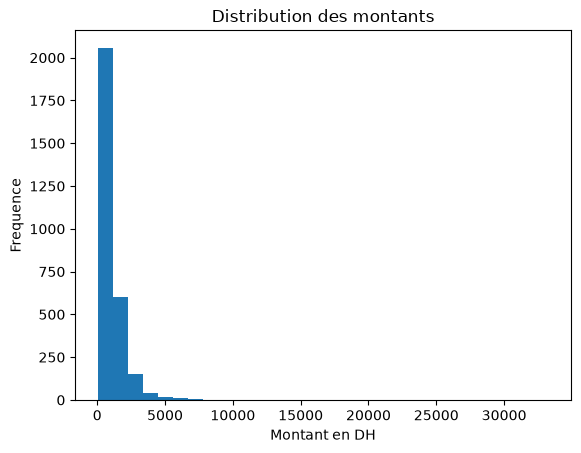

In [11]:
plt.hist(df["montant_dh"].dropna(), bins=30)
plt.title("Distribution des montants")
plt.xlabel("Montant en DH")
plt.ylabel("Frequence")
plt.show()

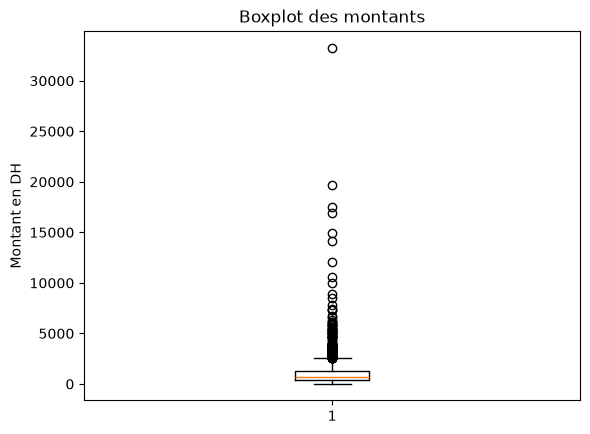

In [12]:
plt.boxplot(df["montant_dh"].dropna())
plt.title("Boxplot des montants")
plt.ylabel("Montant en DH")
plt.show()

In [13]:
df["fraude"].value_counts()

fraude
0    2742
1     258
Name: count, dtype: int64

In [14]:
df["fraude"].value_counts(normalize=True) * 100

fraude
0    91.4
1     8.6
Name: proportion, dtype: float64

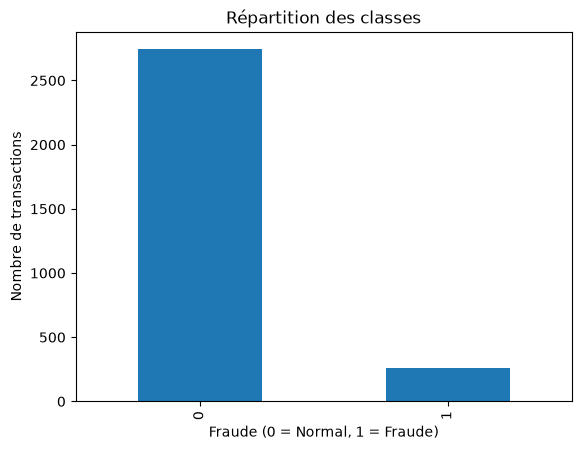

In [15]:
df["fraude"].value_counts().plot(kind="bar")
plt.title("Répartition des classes")
plt.xlabel("Fraude (0 = Normal, 1 = Fraude)")
plt.ylabel("Nombre de transactions")
plt.show()

In [16]:
X = df.drop(columns=[
    "id_operation",
    "id_client",
    "resultat_enquete",
    "fraude"
])

y = df["fraude"]

In [17]:
X.head()

,montant_dh,anciennete_mois,nb_ops_24h,heure,canal,appareil,region,international
0,5396.62,90.0,6.0,11,site_web,mobile,Marrakech-Safi,non
1,438.41,55.0,2.0,22,application,mobile,Souss-Massa,non
2,2846.79,NaN,1.0,10,telephone,ordinateur,Casablanca-Settat,non
3,914.14,127.0,4.0,7,application,mobile,Casablanca-Settat,non
4,228.23,110.0,4.0,5,application,terminal,Casablanca-Settat,non


In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [19]:
X_train.shape, X_test.shape

((2400, 8), (600, 8))

In [20]:
numeric_features = [
    "montant_dh",
    "anciennete_mois",
    "nb_ops_24h",
    "heure"
]

categorical_features = [
    "canal",
    "appareil",
    "region",
    "international"
]

In [21]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [22]:
from sklearn.preprocessing import OneHotEncoder

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [23]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

In [24]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

In [25]:
X_train_processed.shape, X_test_processed.shape

((2400, 18), (600, 18))

In [26]:
from sklearn.preprocessing import RobustScaler

robust_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])

In [27]:
from sklearn.preprocessing import StandardScaler, RobustScaler

data = df[["montant_dh"]].dropna()

standard = StandardScaler()
robust = RobustScaler()

standard_result = standard.fit_transform(data)
robust_result = robust.fit_transform(data)

print("StandardScaler:")
print(standard_result[:5])

print("RobustScaler:")
print(robust_result[:5])

StandardScaler:
[[ 3.30777887]
 [-0.44672755]
 [ 1.37697055]
 [-0.08649042]
 [-0.6058822 ]]
RobustScaler:
[[ 5.45143322]
 [-0.31426246]
 [ 2.48634223]
 [ 0.23894412]
 [-0.55867202]]


In [28]:
Q1 = df["montant_dh"].quantile(0.25)
Q3 = df["montant_dh"].quantile(0.75)

print("Q1 =", Q1)
print("Q3 =", Q3)

Q1 = 389.53
Q3 = 1249.48


In [29]:
IQR = Q3 - Q1

print("IQR =", IQR)

IQR = 859.95


In [30]:
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("Limite inferieure =", lower)
print("Limite superieure =", upper)

Limite inferieure = -900.3950000000002
Limite superieure = 2539.405


In [31]:
outliers = df[
    (df["montant_dh"] < lower) |
    (df["montant_dh"] > upper)
]

print("Nombre des outliers =", len(outliers))

Nombre des outliers = 184


In [32]:
outliers[["montant_dh", "fraude"]].head(10)

,montant_dh,fraude
0,5396.62,0
2,2846.79,0
32,10598.93,0
45,2943.87,0
65,14135.85,0
86,3282.37,0
89,2751.34,0
91,2924.74,0
95,2802.07,0
114,3862.70,0


In [33]:
df["montant_clip"] = df["montant_dh"].clip(
    lower=lower,
    upper=upper
)

In [34]:
df[["montant_dh", "montant_clip"]].head(10)

,montant_dh,montant_clip
0,5396.62,2539.405
1,438.41,438.410
2,2846.79,2539.405
3,914.14,914.140
4,228.23,228.230
5,1443.65,1443.650
6,112.06,112.060
7,2260.29,2260.290
8,1103.46,1103.460
9,624.20,624.200


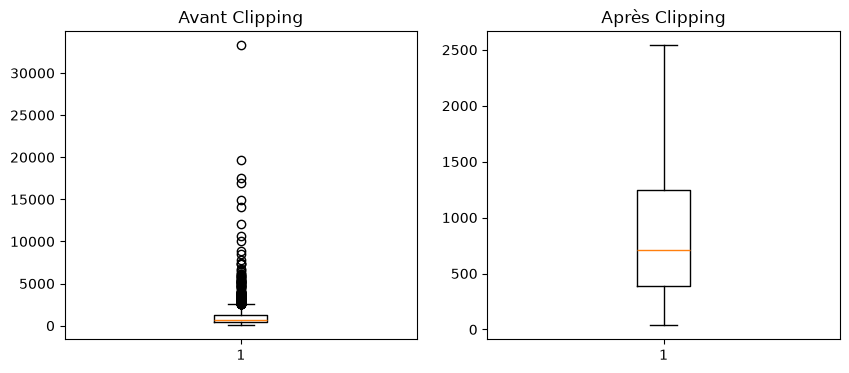

In [35]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.boxplot(df["montant_dh"].dropna())
plt.title("Avant Clipping")

plt.subplot(1, 2, 2)
plt.boxplot(df["montant_clip"].dropna())
plt.title("Après Clipping")

plt.show()

In [36]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
from sklearn.impute import SimpleImputer

# معالجة القيم المفقودة
imputer = SimpleImputer(strategy="median")
montants = imputer.fit_transform(X_train[["montant_dh"]])

# تطبيق طرق التوحيد الثلاث
minmax = MinMaxScaler()
standard = StandardScaler()
robust = RobustScaler()

resultats = pd.DataFrame({
    "Original": montants.flatten(),
    "MinMax": minmax.fit_transform(montants).flatten(),
    "Standard": standard.fit_transform(montants).flatten(),
    "Robust": robust.fit_transform(montants).flatten()
})

resultats.head()

,Original,MinMax,Standard,Robust
0,419.53,0.011524,-0.452796,-0.356740
1,533.01,0.014938,-0.367320,-0.217748
2,477.87,0.013279,-0.408852,-0.285284
3,2518.08,0.074648,1.127884,2.213595
4,394.74,0.010779,-0.471468,-0.387103


In [38]:
idx_max = X_train["montant_dh"].idxmax()

valeur_max = X_train.loc[[idx_max], ["montant_dh"]].values

comparaison = pd.DataFrame({
    "Original": valeur_max.flatten(),
    "MinMax": minmax.transform(valeur_max).flatten(),
    "Standard": standard.transform(valeur_max).flatten(),
    "Robust": robust.transform(valeur_max).flatten()
})

comparaison

,Original,MinMax,Standard,Robust
0,33281.23,1.0,24.299442,39.892755


In [39]:
nouveau_montant = np.array([[50000]])

print(minmax.transform(nouveau_montant))

[[1.5028985]]


In [40]:
y_train.value_counts()

fraude
0    2194
1     206
Name: count, dtype: int64

In [41]:
y_train.value_counts(normalize=True) * 100

fraude
0    91.416667
1     8.583333
Name: proportion, dtype: float64

In [42]:
from imblearn.over_sampling import RandomOverSampler

ros = RandomOverSampler(random_state=42)

X_train_over, y_train_over = ros.fit_resample(X_train, y_train)

In [43]:
y_train_over.value_counts()

fraude
0    2194
1    2194
Name: count, dtype: int64

In [44]:
from imblearn.under_sampling import RandomUnderSampler

rus = RandomUnderSampler(random_state=42)

X_train_under, y_train_under = rus.fit_resample(X_train, y_train)

In [45]:
y_train_under.value_counts()

fraude
0    206
1    206
Name: count, dtype: int64

In [46]:
from imblearn.over_sampling import SMOTE

In [48]:
X_train_clean = X_train.copy()

for col in numeric_features:
    X_train_clean[col] = X_train_clean[col].fillna(
        X_train_clean[col].median()
    )

for col in categorical_features:
    X_train_clean[col] = X_train_clean[col].fillna(
        X_train_clean[col].mode()[0]
    )

In [49]:
X_train_smote, y_train_smote = smotenc.fit_resample(
    X_train_clean,
    y_train
)

In [50]:
y_train_smote.value_counts()

fraude
0    2194
1    2194
Name: count, dtype: int64

In [51]:
y_test.value_counts()

fraude
0    548
1     52
Name: count, dtype: int64

In [52]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [53]:
preprocessor_final = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

In [54]:
X_train_final = preprocessor_final.fit_transform(X_train)

X_test_final = preprocessor_final.transform(X_test)

In [55]:
X_train_final.shape, X_test_final.shape

((2400, 18), (600, 18))

In [56]:
import numpy as np

print("Valeurs manquantes dans X_train :",
      np.isnan(X_train_final.data).any())

print("Valeurs manquantes dans X_test :",
      np.isnan(X_test_final.data).any())

Valeurs manquantes dans X_train : False
Valeurs manquantes dans X_test : False


In [57]:
X_test_unknown = X_test.copy()

X_test_unknown.loc[X_test_unknown.index[0], "canal"] = "canal_inconnu"

X_test_unknown_final = preprocessor_final.transform(X_test_unknown)

print(X_test_unknown_final.shape)

(600, 18)


In [59]:
OneHotEncoder(handle_unknown="ignore")

,"handle_unknown handle_unknown: {'error', 'ignore', 'infrequent_if_exist', 'warn'}, default='error'Specifies the way unknown categories are handled during :meth:`transform`.- 'error' : Raise an error if an unknown category is present during transform.- 'ignore' : When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will be all zeros. In the inverse transform, an unknown category will be denoted as None.- 'infrequent_if_exist' : When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will map to the infrequent category if it exists. The infrequent category will be mapped to the last position in the encoding. During inverse transform, an unknown category will be mapped to the category denoted `'infrequent'` if it exists. If the `'infrequent'` category does not exist, then :meth:`transform` and :meth:`inverse_transform` will handle an unknown category as with `handle_unknown='ignore'`. Infrequent categories exist based on `min_frequency` and `max_categories`. Read more in the :ref:`User Guide <encoder_infrequent_categories>`.- 'warn' : When an unknown category is encountered during transform a warning is issued, and the encoding then proceeds as described for `handle_unknown=""infrequent_if_exist""`... versionchanged:: 1.1 `'infrequent_if_exist'` was added to automatically handle unknown categories and infrequent categories... versionadded:: 1.6 The option `""warn""` was added in 1.6.",'ignore'
,"categories categories: 'auto' or a list of array-like, default='auto'Categories (unique values) per feature:- 'auto' : Determine categories automatically from the training data.- list : ``categories[i]`` holds the categories expected in the ith column. The passed categories should not mix strings and numeric values within a single feature, and should be sorted in case of numeric values.The used categories can be found in the ``categories_`` attribute... versionadded:: 0.20",'auto'
,"drop drop: {'first', 'if_binary'} or an array-like of shape (n_features,), default=NoneSpecifies a methodology to use to drop one of the categories perfeature. This is useful in situations where perfectly collinearfeatures cause problems, such as when feeding the resulting datainto an unregularized linear regression model.However, dropping one category breaks the symmetry of the originalrepresentation and can therefore induce a bias in downstream models,for instance for penalized linear classification or regression models.- None : retain all features (the default).- 'first' : drop the first category in each feature. If only one category is present, the feature will be dropped entirely.- 'if_binary' : drop the first category in each feature with two categories. Features with 1 or more than 2 categories are left intact.- array : ``drop[i]`` is the category in feature ``X[:, i]`` that should be dropped.When `max_categories` or `min_frequency` is configured to groupinfrequent categories, the dropping behavior is handled after thegrouping... versionadded:: 0.21 The parameter `drop` was added in 0.21... versionchanged:: 0.23 The option `drop='if_binary'` was added in 0.23... versionchanged:: 1.1 Support for dropping infrequent categories.",None
,"sparse_output sparse_output: bool, default=TrueWhen ``True``, it returns a SciPy sparse matrix/arrayin ""Compressed Sparse Row"" (CSR) format... versionadded:: 1.2 `sparse` was renamed to `sparse_output`",True
,"dtype dtype: number type, default=np.float64Desired dtype of output.",<class 'numpy.float64'>
,"min_frequency min_frequency: int or float, default=NoneSpecifies the minimum frequency below which a category will beconsidered infrequent.- If `int`, categories with a smaller cardinality will be considered infrequent.- If `float`, categories with a smaller cardinality than `min_frequency * n_samples` will be considered infrequent... versionadded:: 1.1 Read more in the :ref:`User Guide <encoder_infrequen

In [60]:
import joblib

joblib.dump(preprocessor_final, "preprocessor_final.pkl")

['preprocessor_final.pkl']

In [61]:
preprocessor_loaded = joblib.load("preprocessor_final.pkl")

X_test_loaded = preprocessor_loaded.transform(X_test)

print(X_test_loaded.shape)

(600, 18)


In [62]:
numeric_features = ["montant_dh", "anciennete_mois", "nb_ops_24h", "heure"]

categorical_features = ["canal", "appareil", "region", "international"]

print("Variables numériques :", numeric_features)
print("Variables catégorielles :", categorical_features)

Variables numériques : ['montant_dh', 'anciennete_mois', 'nb_ops_24h', 'heure']
Variables catégorielles : ['canal', 'appareil', 'region', 'international']


In [63]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

X_train_num = numeric_pipeline.fit_transform(
    X_train[numeric_features]
)

X_test_num = numeric_pipeline.transform(
    X_test[numeric_features]
)

print("Train :", X_train_num.shape)
print("Test :", X_test_num.shape)

Train : (2400, 4)
Test : (600, 4)


In [64]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

X_train_cat = categorical_pipeline.fit_transform(
    X_train[categorical_features]
)

X_test_cat = categorical_pipeline.transform(
    X_test[categorical_features]
)

print("Train :", X_train_cat.shape)
print("Test :", X_test_cat.shape)

Train : (2400, 14)
Test : (600, 14)


In [65]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Train :", X_train_processed.shape)
print("Test :", X_test_processed.shape)

Train : (2400, 18)
Test : (600, 18)


In [66]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler
import pandas as pd

# Remplacer les valeurs manquantes
imputer = SimpleImputer(strategy="median")
montants = imputer.fit_transform(X_train[["montant_dh"]])

# Créer les deux scalers
standard = StandardScaler()
robust = RobustScaler()

# Calculer les paramètres sur les données d'entraînement
standard.fit(montants)
robust.fit(montants)

# Choisir un montant ordinaire et un montant très élevé
montant_normal = montants[0][0]
montant_eleve = montants.max()

comparaison = pd.DataFrame({
    "Montant original": [montant_normal, montant_eleve],
    "StandardScaler": standard.transform(
        [[montant_normal], [montant_eleve]]
    ).flatten(),
    "RobustScaler": robust.transform(
        [[montant_normal], [montant_eleve]]
    ).flatten()
}, index=["Montant ordinaire", "Montant très élevé"])

print(comparaison)

                    Montant original  StandardScaler  RobustScaler
Montant ordinaire             419.53       -0.452796     -0.356740
Montant très élevé          33281.23       24.299442     39.892755


In [67]:
Q1 = X_train["montant_dh"].quantile(0.25)
Q3 = X_train["montant_dh"].quantile(0.75)

IQR = Q3 - Q1

print("Q1 =", Q1)
print("Q3 =", Q3)
print("IQR =", IQR)

Q1 = 393.095
Q3 = 1249.8775
IQR = 856.7825


In [68]:
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = X_train[
    (X_train["montant_dh"] < lower_bound) |
    (X_train["montant_dh"] > upper_bound)
]

print("Limite inférieure :", lower_bound)
print("Limite supérieure :", upper_bound)
print("Nombre de valeurs extrêmes :", len(outliers))

display(outliers.head(5))

Limite inférieure : -892.0787499999999
Limite supérieure : 2535.05125
Nombre de valeurs extrêmes : 146


,montant_dh,anciennete_mois,nb_ops_24h,heure,canal,appareil,region,international
1601,2940.62,22.0,3.0,9,telephone,mobile,Casablanca-Settat,non
1348,3449.17,154.0,2.0,14,NaN,terminal,Casablanca-Settat,non
2660,33281.23,34.0,4.0,17,application,mobile,Autre,non
1489,3988.17,137.0,3.0,19,agence,mobile,Casablanca-Settat,non
2049,3942.99,136.0,4.0,16,application,mobile,Draa-Tafilalet,non


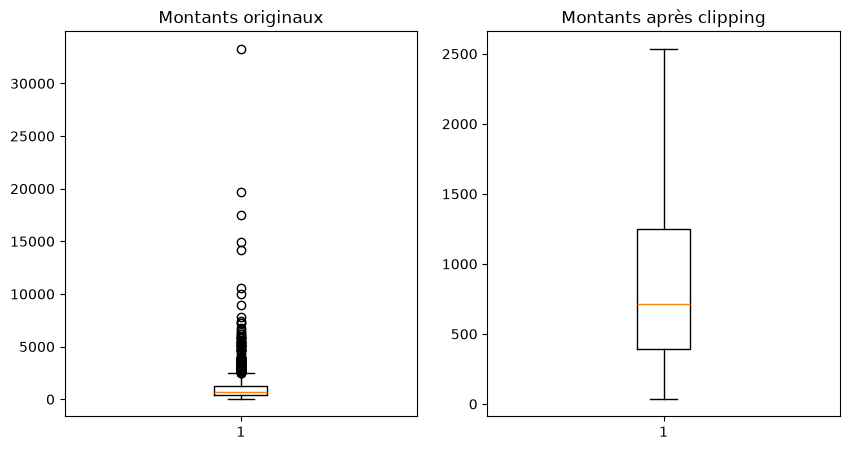

In [69]:
import matplotlib.pyplot as plt

# Limiter les montants selon les seuils calculés
X_train_clip = X_train.copy()

X_train_clip["montant_dh"] = X_train_clip["montant_dh"].clip(
    lower=lower_bound,
    upper=upper_bound
)

# Comparer les deux boxplots
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.boxplot(X_train["montant_dh"].dropna())
plt.title("Montants originaux")

plt.subplot(1, 2, 2)
plt.boxplot(X_train_clip["montant_dh"].dropna())
plt.title("Montants après clipping")

plt.show()

In [70]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
import pandas as pd

# Remplacer les valeurs manquantes
imputer = SimpleImputer(strategy="median")

X_train_montant = imputer.fit_transform(X_train[["montant_dh"]])
X_test_montant = imputer.transform(X_test[["montant_dh"]])

# MinMaxScaler
scaler_minmax = MinMaxScaler()
train_minmax = scaler_minmax.fit_transform(X_train_montant)
test_minmax = scaler_minmax.transform(X_test_montant)

# StandardScaler
scaler_standard = StandardScaler()
train_standard = scaler_standard.fit_transform(X_train_montant)
test_standard = scaler_standard.transform(X_test_montant)

# RobustScaler
scaler_robust = RobustScaler()
train_robust = scaler_robust.fit_transform(X_train_montant)
test_robust = scaler_robust.transform(X_test_montant)

# Comparer les résultats sur les données de test
resultats = pd.DataFrame({
    "Original": X_test_montant.flatten()[:5],
    "MinMaxScaler": test_minmax.flatten()[:5],
    "StandardScaler": test_standard.flatten()[:5],
    "RobustScaler": test_robust.flatten()[:5]
})

display(resultats)

,Original,MinMaxScaler,StandardScaler,RobustScaler
0,795.50,0.022833,-0.169606,0.103754
1,1144.86,0.033342,0.093541,0.531655
2,259.10,0.006698,-0.573635,-0.553237
3,347.80,0.009367,-0.506824,-0.444596
4,451.36,0.012482,-0.428820,-0.317754


In [71]:
import pandas as pd

# Choisir trois montants habituels et un montant très élevé
montants_choisis = pd.DataFrame({
    "montant_dh": [
        419.53,
        533.01,
        477.87,
        X_train["montant_dh"].max()
    ]
})

# Remplacer les valeurs manquantes si nécessaire
montants_imputes = imputer.transform(montants_choisis)

# Créer le tableau de comparaison
resultats = pd.DataFrame({
    "Montant original": montants_imputes.flatten(),
    "MinMaxScaler": scaler_minmax.transform(montants_imputes).flatten(),
    "StandardScaler": scaler_standard.transform(montants_imputes).flatten(),
    "RobustScaler": scaler_robust.transform(montants_imputes).flatten()
})

display(resultats)

,Montant original,MinMaxScaler,StandardScaler,RobustScaler
0,419.53,0.011524,-0.452796,-0.356740
1,533.01,0.014938,-0.367320,-0.217748
2,477.87,0.013279,-0.408852,-0.285284
3,33281.23,1.000000,24.299442,39.892755


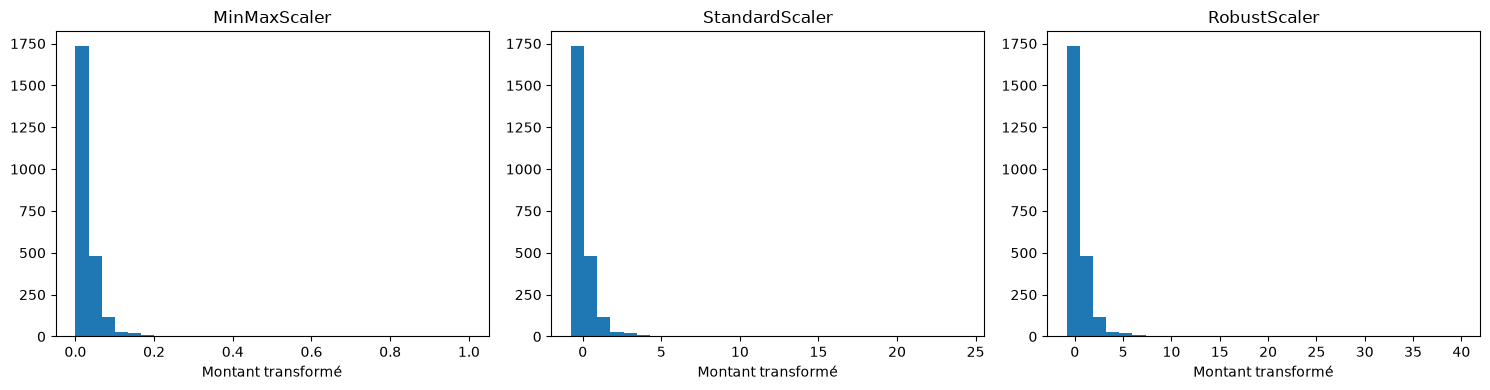

In [72]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.hist(train_minmax, bins=30)
plt.title("MinMaxScaler")
plt.xlabel("Montant transformé")

plt.subplot(1, 3, 2)
plt.hist(train_standard, bins=30)
plt.title("StandardScaler")
plt.xlabel("Montant transformé")

plt.subplot(1, 3, 3)
plt.hist(train_robust, bins=30)
plt.title("RobustScaler")
plt.xlabel("Montant transformé")

plt.tight_layout()
plt.show()

In [73]:
# Créer une nouvelle transaction
nouveau_montant = [[50000]]

# Appliquer MinMaxScaler
valeur_transformee = scaler_minmax.transform(nouveau_montant)

print("Montant original :", 50000)
print("Montant transformé :", valeur_transformee[0][0])

Montant original : 50000
Montant transformé : 1.5028984966680523


In [3]:
import pandas as pd

df = pd.read_csv("transactions_TP2.csv")

print(df.shape)
df.head()

(3045, 12)


,id_operation,id_client,montant_dh,anciennete_mois,nb_ops_24h,heure,canal,appareil,region,international,resultat_enquete,fraude
0,OP02438,C10278,5396.62,90.0,6.0,11,site_web,mobile,Marrakech-Safi,non,aucune_fraude,0
1,OP00157,C10019,438.41,55.0,2.0,22,application,mobile,Souss-Massa,non,aucune_fraude,0
2,OP01987,C10604,2846.79,NaN,1.0,10,telephone,ordinateur,Casablanca-Settat,non,aucune_fraude,0
3,OP00207,C10330,914.14,127.0,4.0,7,application,mobile,Casablanca-Settat,non,aucune_fraude,0
4,OP00738,C10380,228.23,110.0,4.0,5,application,terminal,Casablanca-Settat,non,aucune_fraude,0


In [4]:
# Supprimer les doublons
df = df.drop_duplicates(subset=["id_operation"])

# Séparer les variables X et y
X = df.drop(columns=[
    "id_operation",
    "id_client",
    "resultat_enquete",
    "fraude"
])

y = df["fraude"]

# Diviser les données
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(y_train.shape)

(2400, 8)
(2400,)


In [5]:
print(y_train.value_counts())

print(y_train.value_counts(normalize=True) * 100)

rapport = y_train.value_counts()[0] / y_train.value_counts()[1]

print("Rapport entre les classes :", rapport)

fraude
0    2194
1     206
Name: count, dtype: int64
fraude
0    91.416667
1     8.583333
Name: proportion, dtype: float64
Rapport entre les classes : 10.650485436893204


In [6]:
from imblearn.over_sampling import RandomOverSampler

# Avant le rééquilibrage
print("Avant :")
print(y_train.value_counts())

# Appliquer RandomOverSampler
ros = RandomOverSampler(random_state=42)

X_train_over, y_train_over = ros.fit_resample(X_train, y_train)

# Après le rééquilibrage
print("\nAprès :")
print(y_train_over.value_counts())

print("\nNombre de lignes avant :", len(y_train))
print("Nombre de lignes après :", len(y_train_over))

Avant :
fraude
0    2194
1     206
Name: count, dtype: int64

Après :
fraude
0    2194
1    2194
Name: count, dtype: int64

Nombre de lignes avant : 2400
Nombre de lignes après : 4388


In [7]:
from imblearn.under_sampling import RandomUnderSampler

# Nombre de lignes avant
print("Avant :")
print(y_train.value_counts())

# Appliquer RandomUnderSampler
rus = RandomUnderSampler(random_state=42)

X_train_under, y_train_under = rus.fit_resample(X_train, y_train)

# Nombre de lignes après
print("\nAprès :")
print(y_train_under.value_counts())

print("\nLignes conservées :", len(y_train_under))
print("Lignes supprimées :", len(y_train) - len(y_train_under))

Avant :
fraude
0    2194
1     206
Name: count, dtype: int64

Après :
fraude
0    206
1    206
Name: count, dtype: int64

Lignes conservées : 412
Lignes supprimées : 1988


In [8]:
import numpy as np
from imblearn.over_sampling import SMOTE

# Petit exemple avec deux variables numériques
X_exemple = np.array([
    [10, 20],
    [12, 22],
    [14, 24],
    [30, 40],
    [35, 45],
    [40, 50]
])

y_exemple = np.array([1, 1, 1, 0, 0, 0])

# Appliquer SMOTE
smote = SMOTE(random_state=42, k_neighbors=2)

X_synthetique, y_synthetique = smote.fit_resample(
    X_exemple, y_exemple
)

print("Observations réelles de la classe minoritaire :")
print(X_exemple[y_exemple == 1])

print("\nNouvelles observations synthétiques :")
print(X_synthetique[len(X_exemple):])

Observations réelles de la classe minoritaire :
[[10 20]
 [12 22]
 [14 24]]

Nouvelles observations synthétiques :
[]


In [9]:
import pandas as pd

tableau = pd.DataFrame({
    "Avant rééquilibrage": y_train.value_counts().sort_index(),
    "Après RandomOverSampler": y_train_over.value_counts().sort_index(),
    "Après RandomUnderSampler": y_train_under.value_counts().sort_index()
})

tableau.index.name = "Classe fraude"

display(tableau)

print("Groupe de vérification :")
print(y_test.value_counts().sort_index())

,Avant rééquilibrage,Après RandomOverSampler,Après RandomUnderSampler
Classe fraude,,,
0,2194,2194,206
1,206,2194,206


Groupe de vérification :
fraude
0    548
1     52
Name: count, dtype: int64


In [11]:
numeric_features = [
    "montant_dh",
    "anciennete_mois",
    "nb_ops_24h",
    "heure"
]

categorical_features = [
    "canal",
    "appareil",
    "region",
    "international"
]

In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, OneHotEncoder

# Traitement des variables numériques
numeric_pipeline_final = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])

# Traitement des variables catégorielles
categorical_pipeline_final = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# ColumnTransformer final
preprocessor_final = ColumnTransformer(transformers=[
    ("num", numeric_pipeline_final, numeric_features),
    ("cat", categorical_pipeline_final, categorical_features)
])

print("Préprocesseur final créé avec succès.")

Préprocesseur final créé avec succès.


In [13]:
# Calculer les paramètres sur le groupe de référence
X_train_final = preprocessor_final.fit_transform(X_train)

# Appliquer le même transformateur au groupe de vérification
X_test_final = preprocessor_final.transform(X_test)

# Vérifier les dimensions
print("Dimensions du groupe de référence :", X_train_final.shape)
print("Dimensions du groupe de vérification :", X_test_final.shape)

# Vérifier les valeurs manquantes
import numpy as np

print("Valeurs manquantes dans le groupe de référence :",
      np.isnan(X_train_final).sum())

print("Valeurs manquantes dans le groupe de vérification :",
      np.isnan(X_test_final).sum())

Dimensions du groupe de référence : (2400, 18)
Dimensions du groupe de vérification : (600, 18)
Valeurs manquantes dans le groupe de référence : 0
Valeurs manquantes dans le groupe de vérification : 0


In [14]:
# Créer une nouvelle transaction
nouvelle_transaction = pd.DataFrame([{
    "montant_dh": 500,
    "anciennete_mois": 12,
    "nb_ops_24h": 2,
    "heure": 14,
    "canal": "canal_inconnu",
    "appareil": "Mobile",
    "region": "Centre",
    "international": "Non"
}])

# Transformer la nouvelle transaction
nouvelle_transaction_transformed = preprocessor_final.transform(
    nouvelle_transaction
)

print("Transformation réussie !")
print("Dimensions :", nouvelle_transaction_transformed.shape)

Transformation réussie !
Dimensions : (1, 18)


In [15]:
import joblib
import numpy as np

# Enregistrer le préprocesseur
joblib.dump(preprocessor_final, "preprocesseur_final.pkl")

# Recharger le préprocesseur
preprocesseur_charge = joblib.load("preprocesseur_final.pkl")

# Transformer un petit échantillon
echantillon = X_test.head(5)

resultat_original = preprocessor_final.transform(echantillon)
resultat_charge = preprocesseur_charge.transform(echantillon)

# Comparer les résultats
print("Les résultats sont identiques :",
      np.allclose(resultat_original, resultat_charge))

print("Dimensions :", resultat_charge.shape)

Les résultats sont identiques : True
Dimensions : (5, 18)
